# Yarın kaç adam-saat kapasite ayırmalıyız?

Vardiya planı yalnız sipariş adedine bakıyor. Karmaşık sipariş oranı da iş yükünü etkiliyor. Geçmiş 150 günle model kur ve son 30 günü sırayla değerlendir. İkinci senaryoda planlanan hacim geçmişte görülenden büyük.

Karar: Tahmin planlamaya girebilir mi? Geçmiş aralığı aşan bir gün için nasıl kapasite kararı alınır?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def capacity(scenario='default'):
    rng=np.random.default_rng(72103)
    n=180
    volume=rng.integers(800,2200,n)
    complex_share=rng.uniform(.12,.64,n)
    noise=rng.normal(0,3,n)
    if scenario=='peak':
        volume[150:]=rng.integers(2200,2800,n-150)
        complex_share[150:]=rng.uniform(.49,.73,n-150)
    hours=7 + .022*volume + 27*complex_share + noise
    if scenario=='peak':
        hours[150:] += .025*np.maximum(volume[150:]-2200,0)
    raw=pd.DataFrame({'Gün':np.arange(1,n+1),'Sipariş':volume,'Karmaşık payı':complex_share,'Adam-saat':hours,
                      'Bölüm':np.where(np.arange(n)<150,'Eğitim','Final')})
    X=np.column_stack([np.ones(n),volume,complex_share])
    train=X[:150]
    y=hours[:150]
    coef=np.linalg.lstsq(train,y,rcond=None)[0]
    fit=train@coef
    resid=y-fit
    df=len(y)-len(coef)
    rmse=np.sqrt((resid@resid)/df)
    inv=np.linalg.inv(train.T@train)
    pred=X[150:]@coef
    leverage=np.einsum('ij,jk,ik->i',X[150:],inv,X[150:])
    half=stats.t.ppf(.975,df)*rmse*np.sqrt(1+leverage)
    cover=np.mean(np.abs(hours[150:]-pred)<=half)
    ood=(volume[150:]<volume[:150].min())|(volume[150:]>volume[:150].max())|(complex_share[150:]<complex_share[:150].min())|(complex_share[150:]>complex_share[:150].max())
    base=np.mean(y)
    final=raw.iloc[150:].copy()
    final['Tahmin']=pred
    final['Alt %95']=pred-half
    final['Üst %95']=pred+half
    final['Eğitim aralığı dışında']=ood
    fig,ax=plt.subplots(figsize=(8.8,4.3),layout='constrained')
    ax.plot(final.Gün,hours[150:],'.-',color=ORANGE,label='Gerçekleşen')
    ax.plot(final.Gün,pred,color=BLUE,label='Tahmin')
    ax.fill_between(final.Gün,pred-half,pred+half,color=BLUE,alpha=.13,label='Tek gün için model aralığı')
    if np.any(ood):
        ax.scatter(final.Gün[ood],pred[ood],marker='x',color=GRAY,label='Eğitim aralığı dışında')
    ax.set(xlabel='Final günleri',ylabel='Adam-saat',title='Kapasite tahmini son 30 günde nasıl çalışıyor?')
    ax.legend(fontsize=8)
    fig2,ax2=plt.subplots(figsize=(8.8,3.7),layout='constrained')
    ax2.scatter(fit,resid,c=complex_share[:150],cmap='viridis',alpha=.7)
    ax2.axhline(0,ls='--',color=GRAY)
    ax2.set(xlabel='Eğitim tahmini · adam-saat',ylabel='Gerçekleşen − tahmin',title='Artıkların şekli, yayılımı ve uç noktaları')
    t=X[150]
    h0=t@inv@t
    c=stats.t.ppf(.975,df)*rmse
    detail=pd.DataFrame([['Bir günün ortalama yükü',pred[0],pred[0]-c*np.sqrt(h0),pred[0]+c*np.sqrt(h0)],
                         ['Tek bir günün yükü',pred[0],pred[0]-half[0],pred[0]+half[0]]],
                        columns=['151. gün için hedef','Tahmin','Alt %95','Üst %95'])
    mae=np.mean(np.abs(hours[150:]-pred))
    return dict(metrics={'Final MAE · adam-saat':mae,'Ortalama taban MAE':np.mean(np.abs(hours[150:]-base)),
                         'Final kapsama · %':cover*100,'Destek dışında gün':int(ood.sum()),'1.000 sipariş farkı · adam-saat':coef[1]*1000},
        tables=[table(detail,'Ortalama güven aralığı ve tek gözlem tahmin aralığı'),table(final.head(8),'Final dönemin ilk 8 günü')],
        figures=[('Son 30 gün eğitimde kullanılmaz. Pik yükte aralığın dışına çıkan ve geçmişte görülmeyen günleri ayır.',fig),
                 ('Eğitim artıkları sıfır çevresinde sistematik şekil gösteriyorsa formülü ve değişen yayılımı sorgula.',fig2)],
        frames={'kapasite_180_gun':raw,'final_tahminler':final},
        steps=['Önce ilk 150 güne OLS uydur. Sipariş sayısı ve karmaşık iş payını tahmin anında erişilebilir girdiler olarak kullan.',
               'Ortalama için SE = s√h. Tek yeni gözlem için SE = s√(1+h). Artı bir, günün kendi oynaklığıdır.',
               'Son 30 günü zaman sırasıyla test et. Eğitim aralığı dışında iş yükü varsa model aralığına karar garantisi yükleme.'],
        decision='Geçmiş yük aralığını aşan günler için ayrı pik pilotu veya kapasite senaryosu gerekir.' if np.any(ood) else 'Son dönemde model taban tahmini iyileştiriyor. Vardiya kararında tahmin aralığı ve hizmet hedefi için rezervi ayrıca planla.',
        limit='Klasik tahmin aralığı doğrusal ortalama, sabit varyans ve yaklaşık bağımsız normal artık varsayar. Kapsama yalnız 30 sentetik günde ölçülür. Hacim katsayısı nedensel personel etkisi değildir.',
        diagnostics={'coef':coef,'rmse':rmse,'cover':cover,'mae':mae,'ood':ood.sum(),'train_n':150,'test_n':30,'mean_half':c*np.sqrt(h0),'prediction_half':half[0]},
        focus=[['Eğitim','Gün 1–150','Model yalnız geçmişten öğrenir'],['Final','Gün 151–180','İlk kez değerlendirilen dönem'],['Karar',f'{int(ood.sum())} gün','Geçmiş yük aralığının dışında']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Geçmişe benzer yük

151. gün için model tahmini 67.82 adam-saat, tek günün aralık marjı 7.17 adam-saat. Üst uç kaç adam-saat?


Final MAE · adam-saat: 2.7002751281713966
Ortalama taban MAE: 10.060441831055272
Final kapsama · %: 96.66666666666667
Destek dışında gün: 0
1.000 sipariş farkı · adam-saat: 22.35574045063655

Ortalama güven aralığı ve tek gözlem tahmin aralığı
    151. gün için hedef    Tahmin   Alt %95   Üst %95
Bir günün ortalama yükü 67.817038 66.610830 69.023247
     Tek bir günün yükü 67.817038 60.650881 74.983195

Final dönemin ilk 8 günü
 Gün  Sipariş  Karmaşık payı  Adam-saat Bölüm    Tahmin   Alt %95   Üst %95  Eğitim aralığı dışında
 151     2025       0.574847  67.134109 Final 67.817038 60.650881 74.983195                   False
 152     1210       0.462202  39.394669 Final 46.424859 39.315547 53.534170                   False
 153     1123       0.501993  45.792356 Final 45.600489 38.473750 52.727227                   False
 154      885       0.445758  39.121065 Final 38.696131 31.551634 45.840629                   False
 155     2158       0.142901  60.070203 Final 58.626032 51.436205 65

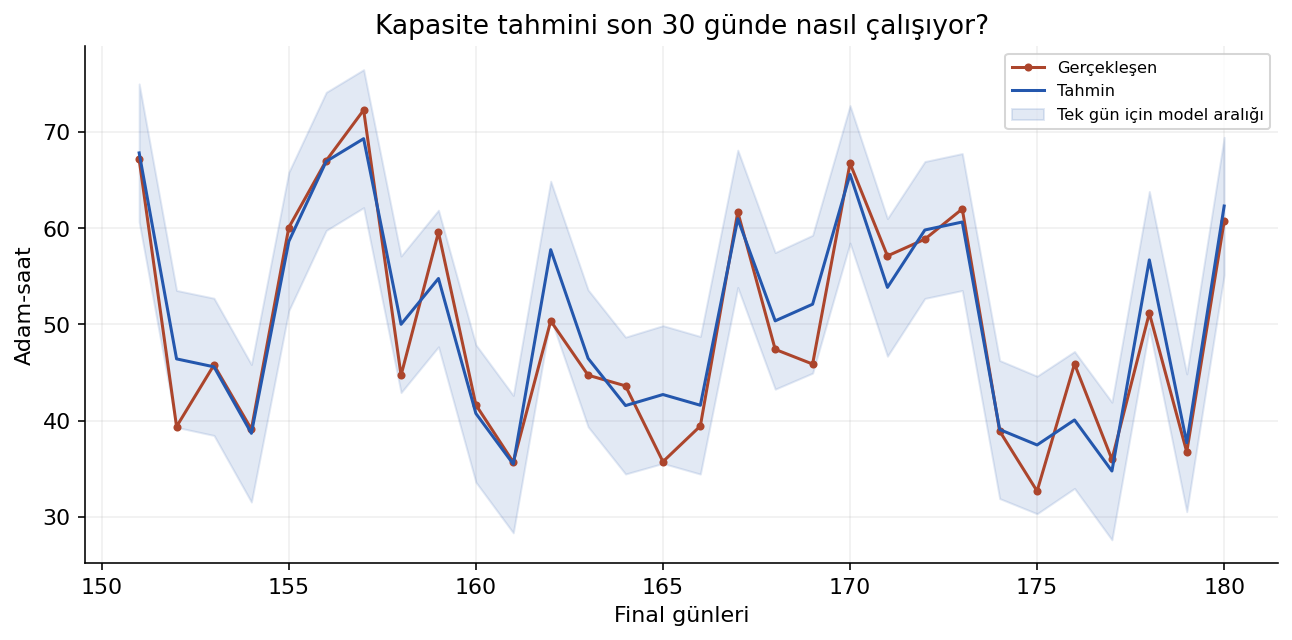

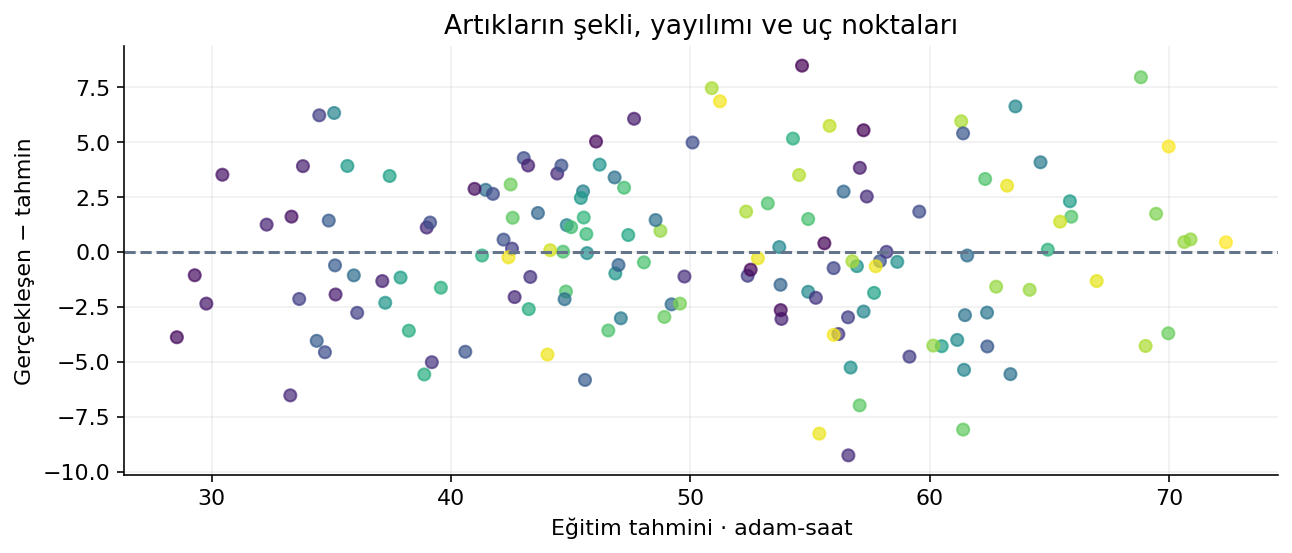

In [2]:
result = capacity('default')
print_result(result)
plt.show()


## Geçmiş aralığını aşan pik yük

151. gün için model tahmini 71.87 adam-saat, tek günün aralık marjı 7.19 adam-saat. Üst uç kaç adam-saat?


Final MAE · adam-saat: 6.481185959456644
Ortalama taban MAE: 35.226528669606104
Final kapsama · %: 56.666666666666664
Destek dışında gün: 30
1.000 sipariş farkı · adam-saat: 22.35574045063655

Ortalama güven aralığı ve tek gözlem tahmin aralığı
    151. gün için hedef    Tahmin   Alt %95   Üst %95
Bir günün ortalama yükü 71.870537 70.551506 73.189569
     Tek bir günün yükü 71.870537 64.684529 79.056546

Final dönemin ilk 8 günü
 Gün  Sipariş  Karmaşık payı  Adam-saat Bölüm    Tahmin   Alt %95   Üst %95  Eğitim aralığı dışında
 151     2310       0.492540  73.931835 Final 71.870537 64.684529 79.056546                    True
 152     2627       0.569026  84.127895 Final 81.111261 73.824593 88.397930                    True
 153     2710       0.721503  99.383122 Final 87.260811 79.869115 94.652507                    True
 154     2286       0.535353  74.512137 Final 72.539675 65.345932 79.733419                    True
 155     2776       0.608641 100.641205 Final 85.557914 78.210445 9

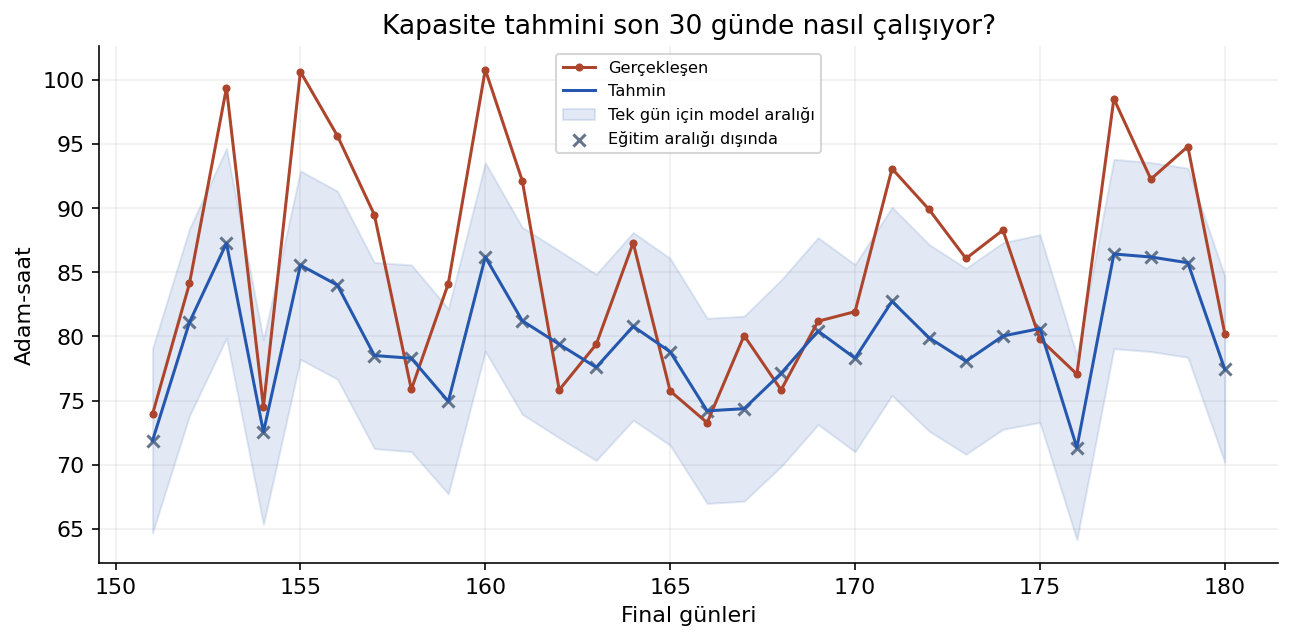

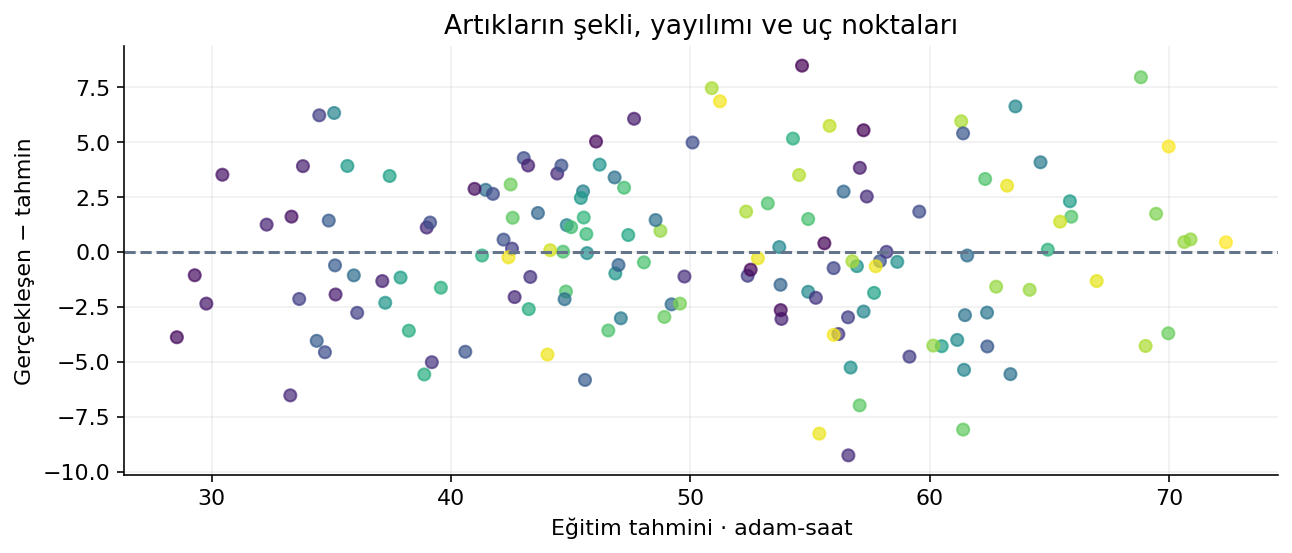

In [3]:
result = capacity('peak')
print_result(result)
plt.show()


## Karar notu

151. gün için iki aralığı kıyasla. Pik senaryosunda hangi girdi geçmiş aralığını aştı, aralık kapsaması ne oldu ve vardiya yöneticisine ne söylersin?

- Ortalama yanıt aralığı ile tek günlük aralığı ayrı anlat.
- Son 30 günün model uydurmada kullanılmadığını göster.
- Pik hacimde ekstrapolasyon ve hizmet riski için plan yaz.